# Context retrain: does training with 20 turns beat 6?
Context.ipynb ended with "next: retrain with a 20-turn window". There, only the context at prediction time changed. Two numbers to beat, both on the full session `valid` (1,012 replies):

- **3.418**: `run1_5ep` at step 2500, trained and evaluated with 6 turns.
- **3.394**: the same adapter evaluated with 20 turns (paired bootstrap by session vs 6 turns: −0.024, 95% CI [−0.031, −0.014]).

Question: if the adapter also sees 20 turns in training, does it go below 3.394?

Setup: `adapters/run1_ctx20`, lr 1e-5, batch 4, 6,755 steps (5 epochs), checkpoints every 100 up to 6700, trained on `data/dataset/session_ctx20`. Same targets and splits as `session/`; only the window grows from 6 to 20 turns. Evaluated on `data/dataset/context/valid_ctx20.jsonl` (byte-identical to `session_ctx20/valid.jsonl`), every 200 steps up to 4000. Selection metric as in decision 15: `nll_ejemplo`, token-weighted mean.

_My prediction:_ This adapter should do better than the previous ones, because every message now gets more context, and in the worst case we stay where we were. So it should improve. Ideally we get below 3.4 loss, and hopefully lower than that. If it doesn't go down, we'll have to work out what is limiting performance.

In [1]:
import json, math, os, random
import numpy as np
import mlx.core as mx
from mlx_lm import load
import matplotlib.pyplot as plt

MODELO = "mlx-community/Qwen2.5-0.5B-Instruct-4bit"
EJEMPLOS_TRAIN = 5404  # session train size; epoch = step * 4 / 5404

In [2]:
# Copied as is from Perplexity.ipynb
def nll_ejemplo(model, tokenizer, messages):
    full = tokenizer.apply_chat_template(messages)
    base_prompt = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True)
    n_tokens = len(full) - len(base_prompt)
    logits = model(mx.array(full)[None])
    logits = logits[0, len(base_prompt)-1:len(full)-1]
    logits = logits.astype(mx.float32)
    logprobs = logits - mx.logsumexp(logits, axis=-1, keepdims=True)
    nll = 0
    for i in range(n_tokens):
        nll -= logprobs[i, full[len(base_prompt) + i]].item()
    mx.clear_cache()
    return (nll, n_tokens)

def medir(model, tokenizer, ruta):
    with open(ruta, "r") as f:
        ejemplos = [json.loads(line) for line in f if line.strip()]
    return [nll_ejemplo(model, tokenizer, e["messages"]) for e in ejemplos]

def resumen(resultados):
    nll = sum(r[0] for r in resultados)
    n = sum(r[1] for r in resultados)
    return nll / n

## Data and checkpoints

In [3]:
ADAPTADOR = "../adapters/run1_ctx20"
VALID_CTX20 = "../data/dataset/context/valid_ctx20.jsonl"
PASOS = list(range(200, 4001, 200))
SALIDA = "results/checkpoints_ctx20.json"
REF_6 = 3.418   # run1_5ep@2500, 6 turns (train and eval)
REF_20 = 3.394  # run1_5ep@2500, 6 turns in train, 20 at eval (Context.ipynb)

with open(VALID_CTX20) as f:
    n_valid = sum(1 for l in f if l.strip())
with open("../data/dataset/context/valid_meta.json") as f:
    sesion = [e["session"] for e in json.load(f)["examples"]]  # for the bootstrap by session
assert n_valid == len(sesion) == 1012, (n_valid, len(sesion))

faltan = [p for p in PASOS if not os.path.exists(f"{ADAPTADOR}/{p:07d}_adapters.safetensors")]
assert not faltan, f"missing checkpoints: {faltan}"
print(f"{n_valid} valid replies, {len(set(sesion))} sessions, {len(PASOS)} checkpoints ({PASOS[0]}-{PASOS[-1]})")

1012 valid replies, 60 sessions, 20 checkpoints (200-4000)


## Measure
Same loop as `curva()` in LearningRate.ipynb, but it keeps the `(nll, tokens)` list per example instead of only the mean, so the bootstrap below can pair replies. It saves after every checkpoint and skips the ones already in the file, so I can stop and resume.

In [4]:
def curva_por_ejemplo(adaptador, ruta_valid, pasos, salida):
    # Resume from a previous partial run if the file exists.
    if os.path.exists(salida):
        with open(salida) as f:
            resultados = json.load(f)
    else:
        resultados = {
            "source": "experiments/ContextRetrain.ipynb",
            "model": MODELO,
            "adapter": adaptador.removeprefix("../"),
            "data": ruta_valid.removeprefix("../"),
            "learning_rate": 1e-5,
            "session": sesion,
            "valid_run1_ctx20": {},
            # Per example, in valid_ctx20.jsonl order: [nll_sum, n_tokens].
            "per_example": {},
        }
    model, tokenizer = load(MODELO, adapter_path=adaptador)
    for paso in pasos:
        if str(paso) in resultados["per_example"]:
            print(f"step {paso:>4}: loss {resultados['valid_run1_ctx20'][str(paso)]:.3f} (cached)")
            continue
        model.load_weights(f"{adaptador}/{paso:07d}_adapters.safetensors", strict=False)
        r = medir(model, tokenizer, ruta_valid)
        resultados["per_example"][str(paso)] = r
        resultados["valid_run1_ctx20"][str(paso)] = resumen(r)
        with open(salida, "w") as f:
            json.dump(resultados, f)
        print(f"step {paso:>4}: loss {resumen(r):.3f}")
    return resultados

ctx20 = curva_por_ejemplo(ADAPTADOR, VALID_CTX20, PASOS, SALIDA)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  200: loss 3.578
step  400: loss 3.511
step  600: loss 3.470
step  800: loss 3.447
step 1000: loss 3.423
step 1200: loss 3.406
step 1400: loss 3.400
step 1600: loss 3.426
step 1800: loss 3.408
step 2000: loss 3.404
step 2200: loss 3.400
step 2400: loss 3.399
step 2600: loss 3.386
step 2800: loss 3.420
step 3000: loss 3.449
step 3200: loss 3.433
step 3400: loss 3.446
step 3600: loss 3.434
step 3800: loss 3.424
step 4000: loss 3.442


## Curve

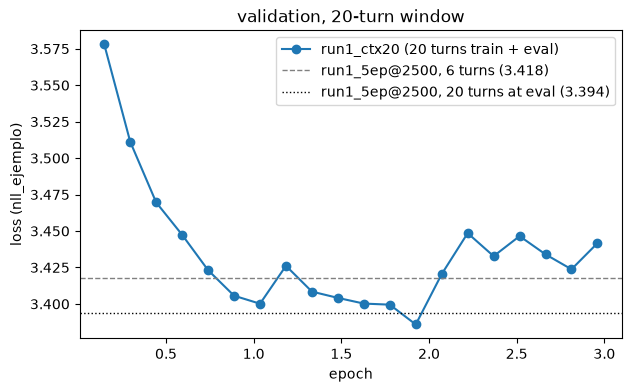

In [5]:
valid = {int(k): v for k, v in sorted(ctx20["valid_run1_ctx20"].items(), key=lambda kv: int(kv[0]))}

fig, eje = plt.subplots(figsize=(7, 4))
eje.plot([p * 4 / EJEMPLOS_TRAIN for p in valid], list(valid.values()), marker="o", label="run1_ctx20 (20 turns train + eval)")
eje.axhline(REF_6, color="gray", linestyle="--", linewidth=1, label=f"run1_5ep@2500, 6 turns ({REF_6})")
eje.axhline(REF_20, color="black", linestyle=":", linewidth=1, label=f"run1_5ep@2500, 20 turns at eval ({REF_20})")
eje.set_title("validation, 20-turn window"); eje.set_xlabel("epoch"); eje.set_ylabel("loss (nll_ejemplo)"); eje.legend()
plt.show()

In [6]:
MEJOR = min(valid, key=valid.get)
ctx20["best_run1_ctx20"] = {"step": MEJOR, "valid_loss": valid[MEJOR]}
with open(SALIDA, "w") as f:
    json.dump(ctx20, f)
print(f"best: step {MEJOR} ({MEJOR * 4 / EJEMPLOS_TRAIN:.2f} epochs), valid {valid[MEJOR]:.3f} "
      f"| vs {REF_6}: {valid[MEJOR] - REF_6:+.3f} | vs {REF_20}: {valid[MEJOR] - REF_20:+.3f}")

best: step 2600 (1.92 epochs), valid 3.386 | vs 3.418: -0.032 | vs 3.394: -0.008


## Is retraining with 20 turns really better?
Paired: same 1,012 replies, same tokens. Main row: same 20-turn context at prediction, only the adapter changes. Second row: against the original setup (6 turns in train and eval). Baseline per-example nll comes from `results/context_v1.json` (run1_5ep@2500, already saved there for ctx 6 and 20). Same method as Context.ipynb: difference = new − old (negative = retraining is better), share of replies whose per-token nll improves, 95% bootstrap CI resampling sessions (1000, with replacement, seed 0).

Caveat: the best step is picked on this same `valid`, so the difference is slightly optimistic. If the CI is close to 0, that matters.

In [7]:
# Copied from Context.ipynb
def por_sesion(resultados, etiquetas):
    sumas = {}
    for (nll, n), s in zip(resultados, etiquetas):
        if s not in sumas:
            sumas[s] = [0.0, 0]
        sumas[s][0] += nll
        sumas[s][1] += n
    return sumas

def perdida(sumas, elegidas):
    nll, n = 0.0, 0
    for s in elegidas:
        nll += sumas.get(s, [0.0, 0])[0]
        n += sumas.get(s, [0.0, 0])[1]
    return nll / n

def comparar_pares(r_antes, r_despues, etiquetas, repeticiones=1000):
    # Same as comparar() in Context.ipynb, but takes the two per-example lists directly.
    media_antes, media_despues = resumen(r_antes), resumen(r_despues)
    mejoran = np.mean([d[0] / d[1] < a[0] / a[1] for a, d in zip(r_antes, r_despues)])
    s_antes, s_despues = por_sesion(r_antes, etiquetas), por_sesion(r_despues, etiquetas)
    sesiones = sorted(s_antes)
    random.seed(0)
    diferencias = []
    for _ in range(repeticiones):
        elegidas = random.choices(sesiones, k=len(sesiones))
        diferencias.append(perdida(s_despues, elegidas) - perdida(s_antes, elegidas))
    bajo, alto = np.percentile(diferencias, [2.5, 97.5])
    return media_antes, media_despues, media_despues - media_antes, mejoran, bajo, alto, len(sesiones)

In [8]:
with open("results/context_v1.json") as f:
    viejo = json.load(f)["per_example"]["adapter"]  # run1_5ep@2500, keys "6" and "20"
nuevo = ctx20["per_example"][str(MEJOR)]

# Sanity checks: same targets (token counts match) and the baselines give back their means.
assert all(a[1] == b[1] for a, b in zip(viejo["20"], nuevo)), "token counts differ: not the same targets"
assert abs(resumen(viejo["20"]) - REF_20) < 0.005, resumen(viejo["20"])
assert abs(resumen(viejo["6"]) - REF_6) < 0.005, resumen(viejo["6"])

print(f"{'baseline':<30} {'old':>6} {'new':>6} {'diff':>7} {'improve':>8} {'95% CI (sessions)':>20}")
for nombre, r_viejo in [("run1_5ep@2500, 20 turns eval", viejo["20"]), ("run1_5ep@2500, 6 turns", viejo["6"])]:
    a, d, dif, mej, lo, hi, n_s = comparar_pares(r_viejo, nuevo, sesion)
    print(f"{nombre:<30} {a:>6.3f} {d:>6.3f} {dif:>+7.3f} {mej:>7.0%} [{lo:+.3f}, {hi:+.3f}] ({n_s})")

baseline                          old    new    diff  improve    95% CI (sessions)
run1_5ep@2500, 20 turns eval    3.394  3.386  -0.008     56% [-0.018, +0.002] (60)
run1_5ep@2500, 6 turns          3.418  3.386  -0.032     58% [-0.045, -0.016] (60)


### Conclusion

Training with 20 turns does not improve performance: best checkpoint 3.386 (step 2600) vs 3.394 for the 6-turn adapter evaluated with 20 turns, paired bootstrap by session −0.008, 95% CI [−0.018, +0.002]. The difference can be noise (neighbouring checkpoints give 3.399 and 3.420). So it's better to keep the adapter trained with up to 6 turns and just give it more context at inference (−0.032 vs 6 turns, CI [−0.045, −0.016]). Context was not the limit. Next: a data curve, training with 25%, 50% and 100% of the train sessions, to see whether the ~3.4 ceiling is lack of data or the floor of the problem.